### Análisis de datos 2 - 4B2026
## Actividad 3. Reducción de dimensionalidad y clustering

**Dataset elegido:** [Communities and Crime](https://archive.ics.uci.edu/dataset/183/communities+and+crime) (UCI Machine Learning Repository)

**Objetivo:** construir un pipeline de ML no supervisado para explorar la estructura socioeconómica de comunidades de EE.UU., reducir la dimensionalidad de sus 100+ variables censales/policiales, agrupar comunidades con perfiles similares y analizar cómo se relaciona esa estructura con la tasa de crímenes violentos (`ViolentCrimesPerPop`), **sin usar el target** para construir la reducción ni los clusters.

**Hipótesis de trabajo:** las comunidades se agrupan naturalmente según su perfil socioeconómico (ingreso, pobreza, desempleo, estructura familiar, densidad poblacional, composición migratoria). Si esa estructura latente está relacionada con la violencia, los clusters obtenidos —aunque ciegos al target— deberían mostrar niveles de criminalidad sistemáticamente distintos entre sí.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 160)
sns.set_style('whitegrid')
RANDOM_STATE = 42

---
## 1. Selección y descripción del dataset

**Communities and Crime.** Cada **fila** representa una **comunidad** (ciudad/pueblo) de Estados Unidos. El dataset combina tres fuentes de datos de la década de 1990:

- **Censo de EE.UU. 1990**: variables socioeconómicas y demográficas (ingreso, raza, edad, empleo, vivienda, estructura familiar, inmigración, etc.)
- **Encuesta LEMAS 1990**: variables policiales (dotación de policías, presupuesto, composición racial de la fuerza, etc.) — *solo disponible para una muestra de departamentos, por lo que tiene ~84% de faltantes*
- **FBI UCR 1995**: la variable objetivo, `ViolentCrimesPerPop` (crímenes violentos cada 100 mil habitantes)

Todas las variables numéricas están **normalizadas entre 0 y 1** (binning de igual intervalo según media y desvío), por lo que conservan la forma de su distribución original pero **no son comparables en magnitud absoluta entre sí** (ej. no tiene sentido comparar directamente `whitePerCap` con `blackPerCap`).

Hay 1994 comunidades y 128 columnas: 5 identificadoras/no predictivas (`state`, `county`, `community`, `communityname`, `fold`), 122 predictoras y el target `ViolentCrimesPerPop`.

Se trata de un **problema de regresión** (target continuo)

In [2]:
# Nombres de columnas según el archivo communities.names (orden oficial UCI)
columns = [
    'state', 'county', 'community', 'communityname', 'fold', 'population', 'householdsize',
    'racepctblack', 'racePctWhite', 'racePctAsian', 'racePctHisp', 'agePct12t21', 'agePct12t29',
    'agePct16t24', 'agePct65up', 'numbUrban', 'pctUrban', 'medIncome', 'pctWWage', 'pctWFarmSelf',
    'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'medFamInc', 'perCapInc', 'whitePerCap',
    'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'NumUnderPov',
    'PctPopUnderPov', 'PctLess9thGrade', 'PctNotHSGrad', 'PctBSorMore', 'PctUnemployed', 'PctEmploy',
    'PctEmplManu', 'PctEmplProfServ', 'PctOccupManu', 'PctOccupMgmtProf', 'MalePctDivorce',
    'MalePctNevMarr', 'FemalePctDiv', 'TotalPctDiv', 'PersPerFam', 'PctFam2Par', 'PctKids2Par',
    'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMomYoungKids', 'PctWorkMom', 'NumIlleg', 'PctIlleg',
    'NumImmig', 'PctImmigRecent', 'PctImmigRec5', 'PctImmigRec8', 'PctImmigRec10', 'PctRecentImmig',
    'PctRecImmig5', 'PctRecImmig8', 'PctRecImmig10', 'PctSpeakEnglOnly', 'PctNotSpeakEnglWell',
    'PctLargHouseFam', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous',
    'PersPerRentOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR',
    'HousVacant', 'PctHousOccup', 'PctHousOwnOcc', 'PctVacantBoarded', 'PctVacMore6Mos',
    'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'OwnOccMedVal',
    'OwnOccHiQuart', 'RentLowQ', 'RentMedian', 'RentHighQ', 'MedRent', 'MedRentPctHousInc',
    'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctForeignBorn',
    'PctBornSameState', 'PctSameHouse85', 'PctSameCity85', 'PctSameState85', 'LemasSwornFT',
    'LemasSwFTPerPop', 'LemasSwFTFieldOps', 'LemasSwFTFieldPerPop', 'LemasTotalReq',
    'LemasTotReqPerPop', 'PolicReqPerOffic', 'PolicPerPop', 'RacialMatchCommPol', 'PctPolicWhite',
    'PctPolicBlack', 'PctPolicHisp', 'PctPolicAsian', 'PctPolicMinor', 'OfficAssgnDrugUnits',
    'NumKindsDrugsSeiz', 'PolicAveOTWorked', 'LandArea', 'PopDens', 'PctUsePubTrans', 'PolicCars',
    'PolicOperBudg', 'LemasPctPolicOnPatr', 'LemasGangUnitDeploy', 'LemasPctOfficDrugUn',
    'PolicBudgPerPop', 'ViolentCrimesPerPop'
]

df = pd.read_csv('communities.data', header=None, names=columns, na_values='?')
df.shape

(1994, 128)

In [3]:
df.head(3)

,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,numbUrban,pctUrban,medIncome,pctWWage,pctWFarmSelf,pctWInvInc,pctWSocSec,pctWPubAsst,pctWRetire,medFamInc,perCapInc,whitePerCap,blackPerCap,indianPerCap,AsianPerCap,...,PctSameHouse85,PctSameCity85,PctSameState85,LemasSwornFT,LemasSwFTPerPop,LemasSwFTFieldOps,LemasSwFTFieldPerPop,LemasTotalReq,LemasTotReqPerPop,PolicReqPerOffic,PolicPerPop,RacialMatchCommPol,PctPolicWhite,PctPolicBlack,PctPolicHisp,PctPolicAsian,PctPolicMinor,OfficAssgnDrugUnits,NumKindsDrugsSeiz,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,0.20,1.0,0.37,0.72,0.34,0.60,0.29,0.15,0.43,0.39,0.40,0.39,0.32,0.27,0.27,...,0.50,0.51,0.64,0.03,0.13,0.96,0.17,0.06,0.18,0.44,0.13,0.94,0.93,0.03,0.07,0.1,0.07,0.02,0.57,0.29,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,0.02,1.0,0.31,0.72,0.11,0.45,0.25,0.29,0.39,0.29,0.37,0.38,0.33,0.16,0.30,...,0.34,0.60,0.52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,0.00,0.0,0.30,0.58,0.19,0.39,0.38,0.40,0.84,0.28,0.27,0.29,0.27,0.07,0.29,...,0.54,0.67,0.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43


---
## 2. Análisis exploratorio y preprocesamiento

### 2.1 Tipos de datos


In [4]:
df.dtypes.value_counts()

float64    125
int64        2
str          1
Name: count, dtype: int64

Todas las variables predictoras son numéricas (ya normalizadas 0-1 por el donante del dataset). La única columna de texto es `communityname`, que es un identificador (no predictivo).

### 2.2 Variable objetivo (`ViolentCrimesPerPop`)



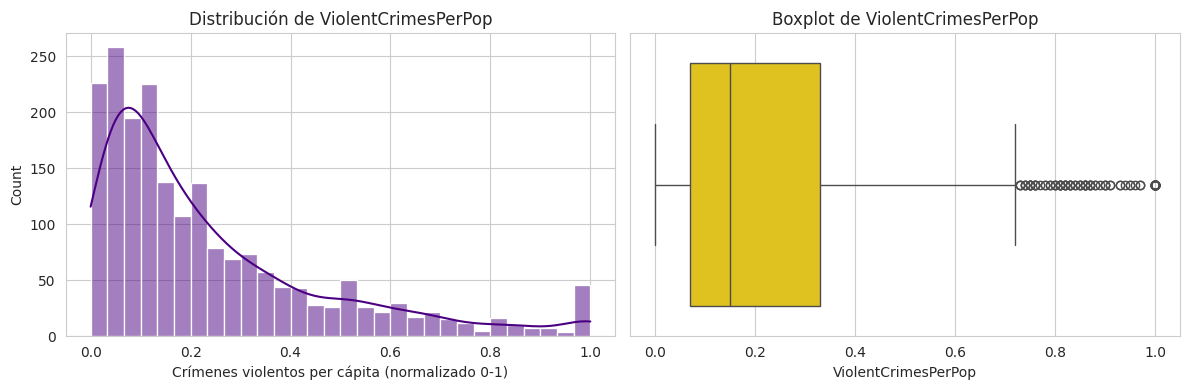

count    1994.000000
mean        0.237979
std         0.232985
min         0.000000
25%         0.070000
50%         0.150000
75%         0.330000
max         1.000000
Name: ViolentCrimesPerPop, dtype: float64

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['ViolentCrimesPerPop'], bins=30, kde=True, ax=axes[0], color='#4b0082')
axes[0].set_title('Distribución de ViolentCrimesPerPop')
axes[0].set_xlabel('Crímenes violentos per cápita (normalizado 0-1)')

sns.boxplot(x=df['ViolentCrimesPerPop'], ax=axes[1], color='#ffd700')
axes[1].set_title('Boxplot de ViolentCrimesPerPop')

plt.tight_layout()
plt.show()

df['ViolentCrimesPerPop'].describe()

La distribución está sesgada a la derecha: la mayoría de las comunidades tienen criminalidad baja, con una cola de comunidades con criminalidad muy alta. Esto es consistente con la naturaleza del fenómeno (la violencia suele concentrarse en un subconjunto de lugares).

### 2.3 Valores faltantes



Columnas con >40% de faltantes: 24
Columnas con faltantes <1%: 1


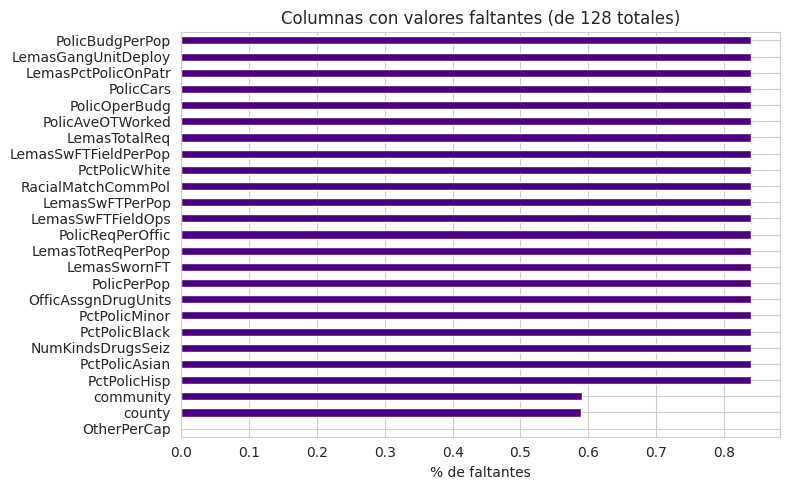

In [6]:
missing_pct = df.isna().mean().sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0]

plt.figure(figsize=(8, 5))
missing_pct.plot(kind='barh', color='#4b0082')
plt.gca().invert_yaxis()
plt.title(f'Columnas con valores faltantes (de {df.shape[1]} totales)')
plt.xlabel('% de faltantes')
plt.tight_layout()
plt.show()

print(f"Columnas con >40% de faltantes: {(missing_pct > 0.4).sum()}")
print(f"Columnas con faltantes <1%: {((missing_pct > 0) & (missing_pct <= 0.01)).sum()}")

Se observan tres grupos:

- **`county` y `community`** (~59% faltante): códigos identificadores, no predictivos.
- **Un bloque de 22 variables LEMAS** (dotación policial, presupuesto, composición racial de la fuerza, etc., ~84% faltante): la encuesta LEMAS solo releva departamentos con más de 100 oficiales (más una muestra aleatoria de departamentos chicos), por lo que la mayoría de las comunidades no tiene estos datos. Imputar un 84% de una columna la volvería poco informativa y sesgaría fuertemente la estructura de distancias que usa el clustering, así que se **eliminan**.
- **`OtherPerCap`**: un único valor faltante (0.05%), se imputa con la mediana.

### 2.4 Selección de variables y preprocesamiento

Pipeline:
1. Eliminar columnas no predictivas (`state`, `county`, `community`, `communityname`, `fold`) y el target.
2. Eliminar las 22 columnas LEMAS con >40% de faltantes.
3. Imputar los faltantes residuales con la mediana.
4. Estandarizar (media 0, desvío 1) — necesario porque PCA/SVD y las distancias euclídeas que usan KMeans/DBSCAN son sensibles a la escala.


In [7]:
non_predictive = ['state', 'county', 'community', 'communityname', 'fold']
high_missing_cols = df.columns[df.isna().mean() > 0.4].tolist()
high_missing_cols = [c for c in high_missing_cols if c not in non_predictive]

target = df['ViolentCrimesPerPop'].copy()
community_names = df['communityname'].copy()
community_state = df['state'].copy()

drop_cols = set(non_predictive) | set(high_missing_cols) | {'ViolentCrimesPerPop'}
X = df.drop(columns=[c for c in drop_cols if c in df.columns])

print(f"Variables no predictivas eliminadas: {len(non_predictive)}")
print(f"Variables LEMAS con alta proporción de faltantes eliminadas: {len(high_missing_cols)}")
print(f"Shape final de X (features): {X.shape}")
print(f"Valores faltantes remanentes: {X.isna().sum().sum()}")

Variables no predictivas eliminadas: 5
Variables LEMAS con alta proporción de faltantes eliminadas: 22
Shape final de X (features): (1994, 100)
Valores faltantes remanentes: 1


In [8]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer = SimpleImputer(strategy='median')
X_imputed = imputer.fit_transform(X)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("X_scaled shape:", X_scaled.shape)
print("Media por columna (debería ser ~0):", X_scaled.mean().round(3))
print("Desvío por columna (debería ser ~1):", X_scaled.std().round(3))

X_scaled shape: (1994, 100)
Media por columna (debería ser ~0): -0.0
Desvío por columna (debería ser ~1): 1.0


---
## 3. Reducción de dimensionalidad y clustering

### 3a. Reducción de dimensionalidad



80% de varianza explicada -> 11 componentes
85% de varianza explicada -> 16 componentes
90% de varianza explicada -> 23 componentes
95% de varianza explicada -> 35 componentes


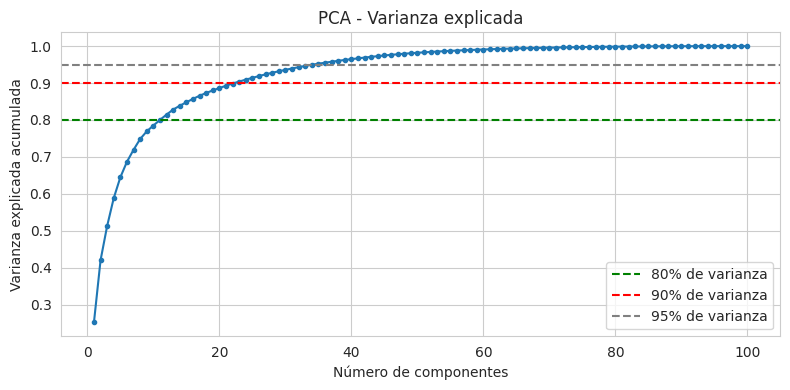

In [9]:
from sklearn.decomposition import PCA, TruncatedSVD

pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
explained_var = pca_full.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)
componentes = np.arange(1, len(explained_var) + 1)

plt.figure(figsize=(8, 4))
plt.plot(componentes, cumulative_var, marker='.')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('PCA - Varianza explicada')
plt.grid(True)
for thresh, color in zip([0.80, 0.90, 0.95], ['green', 'red', 'gray']):
    plt.axhline(y=thresh, color=color, linestyle='--', label=f'{int(thresh*100)}% de varianza')
plt.legend()
plt.tight_layout()
plt.show()

for thresh in [0.80, 0.85, 0.90, 0.95]:
    n = int(np.argmax(cumulative_var >= thresh) + 1)
    print(f"{int(thresh*100)}% de varianza explicada -> {n} componentes")

Se elige conservar **90% de la varianza explicada**, un buen compromiso entre compresión (se redujo de 100 a ~23 dimensiones, un ~77% menos) y preservación de información para que el clustering posterior no pierda estructura relevante.

In [10]:
n_components = int(np.argmax(cumulative_var >= 0.90) + 1)

pca = PCA(n_components=n_components, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print(f"n_components elegidos: {n_components}")
print(f"Shape de la representación reducida: {X_pca.shape}")
print(f"Varianza explicada total: {pca.explained_variance_ratio_.sum():.3f}")

n_components elegidos: 23
Shape de la representación reducida: (1994, 23)
Varianza explicada total: 0.904


#### ¿Qué significan las primeras componentes?

Variables originales que pesan más en PC1 y PC2, las dos direcciones de mayor varianza.

In [11]:
loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=['PC1', 'PC2'])

top_pc1 = loadings['PC1'].abs().sort_values(ascending=False).head(8).index
top_pc2 = loadings['PC2'].abs().sort_values(ascending=False).head(8).index

print("Variables con mayor peso en PC1:")
print(loadings.loc[top_pc1, 'PC1'].round(3))
print("\nVariables con mayor peso en PC2:")
print(loadings.loc[top_pc2, 'PC2'].round(3))

Variables con mayor peso en PC1:
medFamInc           0.183
medIncome           0.182
PctKids2Par         0.175
pctWInvInc          0.174
PctPopUnderPov     -0.173
PctFam2Par          0.172
PctYoungKids2Par    0.171
perCapInc           0.169
Name: PC1, dtype: float64

Variables con mayor peso en PC2:
PctRecImmig10          0.219
PctRecImmig8           0.219
PctRecImmig5           0.217
PctRecentImmig         0.214
PctForeignBorn         0.213
PctSpeakEnglOnly      -0.191
PctNotSpeakEnglWell    0.188
PctPersDenseHous       0.175
Name: PC2, dtype: float64


`PC1` queda dominada por variables de **pobreza/ingreso/estructura familiar** (pobreza, ingreso medio, % familias con dos padres, % hijos no matrimoniales) con signos opuestos entre pobreza y nivel socioeconómico, es decir, es un eje de "nivel socioeconómico". `PC2` recoge variables ligadas a **urbanización/densidad/inmigración**. Esto ya sugiere que la estructura principal de los datos es socioeconómica, coherente con nuestra hipótesis inicial.

### SVD



Varianza explicada total - PCA: 0.9041
Varianza explicada total - SVD: 0.9040
Correlación entre primeras coordenadas PCA y SVD: 1.0000


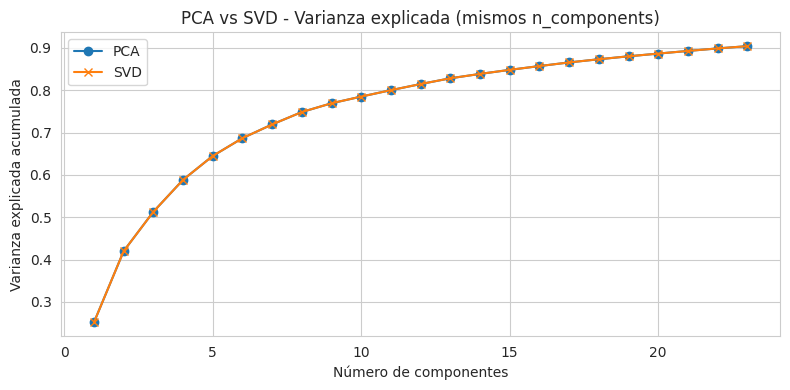

In [12]:
svd = TruncatedSVD(n_components=n_components, random_state=RANDOM_STATE)
X_svd = svd.fit_transform(X_scaled)

plt.figure(figsize=(8, 4))
plt.plot(componentes[:n_components], np.cumsum(pca.explained_variance_ratio_), marker='o', label='PCA')
plt.plot(componentes[:n_components], np.cumsum(svd.explained_variance_ratio_), marker='x', label='SVD')
plt.xlabel('Número de componentes')
plt.ylabel('Varianza explicada acumulada')
plt.title('PCA vs SVD - Varianza explicada (mismos n_components)')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Varianza explicada total - PCA: {pca.explained_variance_ratio_.sum():.4f}")
print(f"Varianza explicada total - SVD: {svd.explained_variance_ratio_.sum():.4f}")
print(f"Correlación entre primeras coordenadas PCA y SVD: {np.corrcoef(X_pca[:,0], X_svd[:,0])[0,1]:.4f}")

Como se estandarozó los datos (media 0), PCA y SVD son prácticamente equivalentes: SVD sobre una matriz centrada **es** PCA (ambos buscan las direcciones de máxima varianza; las diferencias de implementación —truncamiento vs. centrado interno— no cambian la varianza explicada total y las coordenadas quedan perfectamente correlacionadas). Por eso, de acá en adelante se trabaja con **`X_pca`** como la representación reducida para clustering, sin perder generalidad respecto de usar SVD.

### 3b. Clustering

Se entrena y compara **tres** algoritmos de clustering sobre `X_pca` (representación reducida, sin el target):

- **KMeans** (basado en centroides, particiona todo el espacio)
- **DBSCAN** (basado en densidad, puede dejar puntos como "ruido")
- **Agglomerative Clustering / Ward** (jerárquico, como segunda validación de la partición de KMeans)


#### KMeans: selección de *k*

Se prueba varios valores de *k*  **silhouette** (más alto = clusters más separados y compactos, rango [-1,1]), **Davies-Bouldin** (más bajo = mejor) y **Calinski-Harabasz** (más alto = mejor).

In [13]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

k_range = range(2, 11)
results_k = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit(X_pca)
    results_k.append({
        'k': k,
        'silhouette': silhouette_score(X_pca, km.labels_),
        'davies_bouldin': davies_bouldin_score(X_pca, km.labels_),
        'calinski_harabasz': calinski_harabasz_score(X_pca, km.labels_),
        'inertia': km.inertia_,
    })

results_k_df = pd.DataFrame(results_k)
results_k_df

,k,silhouette,davies_bouldin,calinski_harabasz,inertia
0,2,0.181279,1.902274,473.924952,145622.279092
1,3,0.197990,1.676808,428.023957,126065.087271
2,4,0.134434,1.884573,363.542772,116448.022683
3,5,0.148815,1.693317,339.506006,107125.854352
4,6,0.164248,1.582215,327.555393,98840.392658
5,7,0.165139,1.559486,310.217060,93077.996090
6,8,0.141450,1.677815,293.522184,88602.461478
7,9,0.147106,1.704539,278.634799,84914.594721
8,10,0.149214,1.670187,266.356701,81633.029098


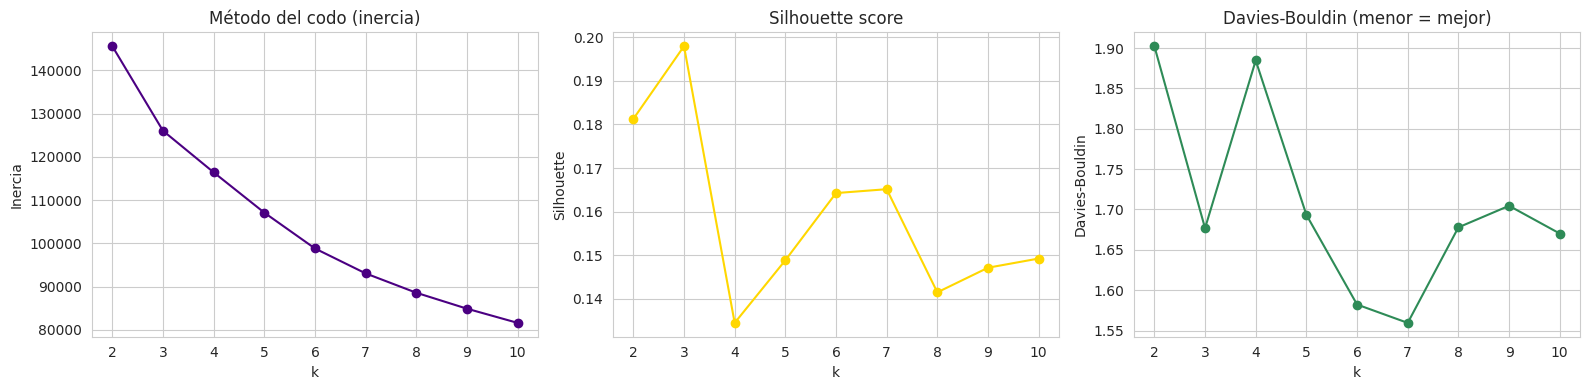

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(results_k_df['k'], results_k_df['inertia'], marker='o', color='#4b0082')
axes[0].set_title('Método del codo (inercia)')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inercia')

axes[1].plot(results_k_df['k'], results_k_df['silhouette'], marker='o', color='#ffd700')
axes[1].set_title('Silhouette score')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette')

axes[2].plot(results_k_df['k'], results_k_df['davies_bouldin'], marker='o', color='#2e8b57')
axes[2].set_title('Davies-Bouldin (menor = mejor)')
axes[2].set_xlabel('k'); axes[2].set_ylabel('Davies-Bouldin')

plt.tight_layout()
plt.show()

No hay un codo muy marcado (esperable: son datos socioeconómicos continuos, no clusters naturalmente esféricos y separados), pero **k=3** maximiza el silhouette score y es de los mejores en Davies-Bouldin/Calinski-Harabasz, además de ser fácilmente interpretable. Elegimos **k=3**.

In [15]:
kmeans = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

pd.Series(kmeans_labels).value_counts().sort_index().rename('n_comunidades').to_frame()

,n_comunidades
0,798
1,976
2,220


#### DBSCAN

Método del **gráfico de distancia al k-ésimo vecino** para elegir `eps`.

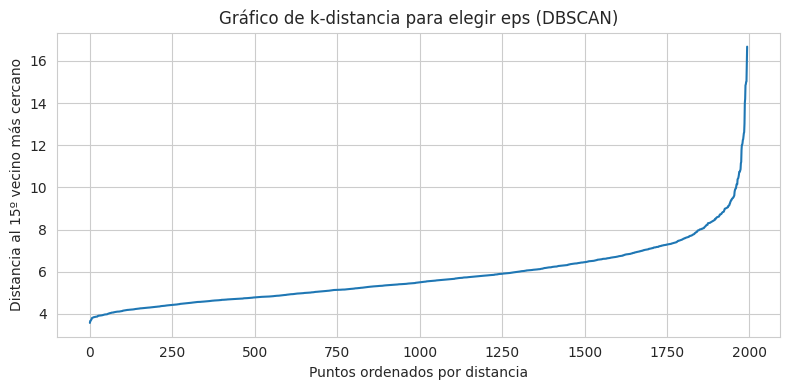

In [16]:
from sklearn.neighbors import NearestNeighbors

min_samples_try = 15
nn = NearestNeighbors(n_neighbors=min_samples_try).fit(X_pca)
distances, _ = nn.kneighbors(X_pca)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel('Puntos ordenados por distancia')
plt.ylabel(f'Distancia al {min_samples_try}º vecino más cercano')
plt.title('Gráfico de k-distancia para elegir eps (DBSCAN)')
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
from sklearn.cluster import DBSCAN

# Barrido de eps / min_samples sobre la representación reducida
dbscan_grid = []
for min_samples in [10, 15, 20]:
    nn = NearestNeighbors(n_neighbors=min_samples).fit(X_pca)
    dist, _ = nn.kneighbors(X_pca)
    kd = np.sort(dist[:, -1])
    for pct in [50, 60, 70, 80]:
        eps = round(np.percentile(kd, pct), 1)
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_pca)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        n_noise = int((labels == -1).sum())
        sil = np.nan
        if n_clusters >= 2:
            mask = labels != -1
            if mask.sum() > 1 and len(set(labels[mask])) > 1:
                sil = silhouette_score(X_pca[mask], labels[mask])
        dbscan_grid.append({
            'min_samples': min_samples, 'eps': eps, 'n_clusters': n_clusters,
            'noise_pts': n_noise, 'noise_pct': round(100*n_noise/len(labels), 1),
            'silhouette_no_noise': sil,
        })

dbscan_grid_df = pd.DataFrame(dbscan_grid)
dbscan_grid_df

,min_samples,eps,n_clusters,noise_pts,noise_pct,silhouette_no_noise
0,10,5.2,3,486,24.4,0.364454
1,10,5.5,4,347,17.4,0.170607
2,10,5.8,2,253,12.7,0.145239
3,10,6.3,1,158,7.9,NaN
4,15,5.5,2,448,22.5,0.450907
5,15,5.8,1,335,16.8,NaN
6,15,6.2,2,217,10.9,0.339775
7,15,6.7,1,131,6.6,NaN
8,20,5.7,1,444,22.3,NaN
9,20,6.1,1,288,14.4,NaN


El barrido muestra un patrón consistente: con parámetros laxos, **todo** queda en un único cluster denso; con parámetros más estrictos, aparece **un cluster gigante** (la enorme mayoría de las comunidades, que forman un continuo de densidad relativamente uniforme) más un puñado de **mini-clusters de comunidades atípicas** (outliers extremos) y bastante **ruido**. Esto es un resultado informativo en sí mismo: **no hay fronteras de densidad naturales** entre grupos de comunidades — la estructura socioeconómica es más un *continuo* que *clusters bien separados por densidad*, justo lo que haría esperar DBSCAN sobre variables macroeconómicas suavemente distribuidas.

Uso de la configuración `min_samples=15, eps=5.5` (silhouette más alto entre las configuraciones con más de un cluster) para continuar la comparación cuantitativa.

In [18]:
dbscan = DBSCAN(eps=5.5, min_samples=15)
dbscan_labels = dbscan.fit_predict(X_pca)

n_clusters_db = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
print(f"DBSCAN encontró {n_clusters_db} clusters (sin contar ruido)")
pd.Series(dbscan_labels).value_counts().sort_index().rename('n_comunidades').to_frame()

DBSCAN encontró 2 clusters (sin contar ruido)


,n_comunidades
-1,448
0,1526
1,20


#### Agglomerative Clustering (Ward)

k=3

In [19]:
from sklearn.cluster import AgglomerativeClustering

agglo = AgglomerativeClustering(n_clusters=3, linkage='ward')
agglo_labels = agglo.fit_predict(X_pca)

pd.Series(agglo_labels).value_counts().sort_index().rename('n_comunidades').to_frame()

,n_comunidades
0,1213
1,157
2,624


### 3c. Evaluación, comparación y selección


In [20]:
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score

def summarize(name, labels, X_ref):
    mask = labels != -1
    n_clusters = len(set(labels[mask])) if mask.sum() else 0
    noise_pct = 100 * (~mask).sum() / len(labels)
    sil = silhouette_score(X_ref[mask], labels[mask]) if n_clusters > 1 else np.nan
    db = davies_bouldin_score(X_ref[mask], labels[mask]) if n_clusters > 1 else np.nan
    return {'algoritmo': name, 'n_clusters': n_clusters, '% ruido/no asignado': round(noise_pct, 1),
            'silhouette': sil, 'davies_bouldin': db}

comparison = pd.DataFrame([
    summarize('KMeans (k=3)', kmeans_labels, X_pca),
    summarize('DBSCAN', dbscan_labels, X_pca),
    summarize('Agglomerative/Ward (k=3)', agglo_labels, X_pca),
]).round(3)
comparison

,algoritmo,n_clusters,% ruido/no asignado,silhouette,davies_bouldin
0,KMeans (k=3),3,0.0,0.198,1.677
1,DBSCAN,2,22.5,0.451,0.658
2,Agglomerative/Ward (k=3),3,0.0,0.161,1.878


In [21]:
print("ARI  KMeans vs Agglomerative:", round(adjusted_rand_score(kmeans_labels, agglo_labels), 3))
print("AMI  KMeans vs Agglomerative:", round(adjusted_mutual_info_score(kmeans_labels, agglo_labels), 3))

ARI  KMeans vs Agglomerative: 0.361
AMI  KMeans vs Agglomerative: 0.412


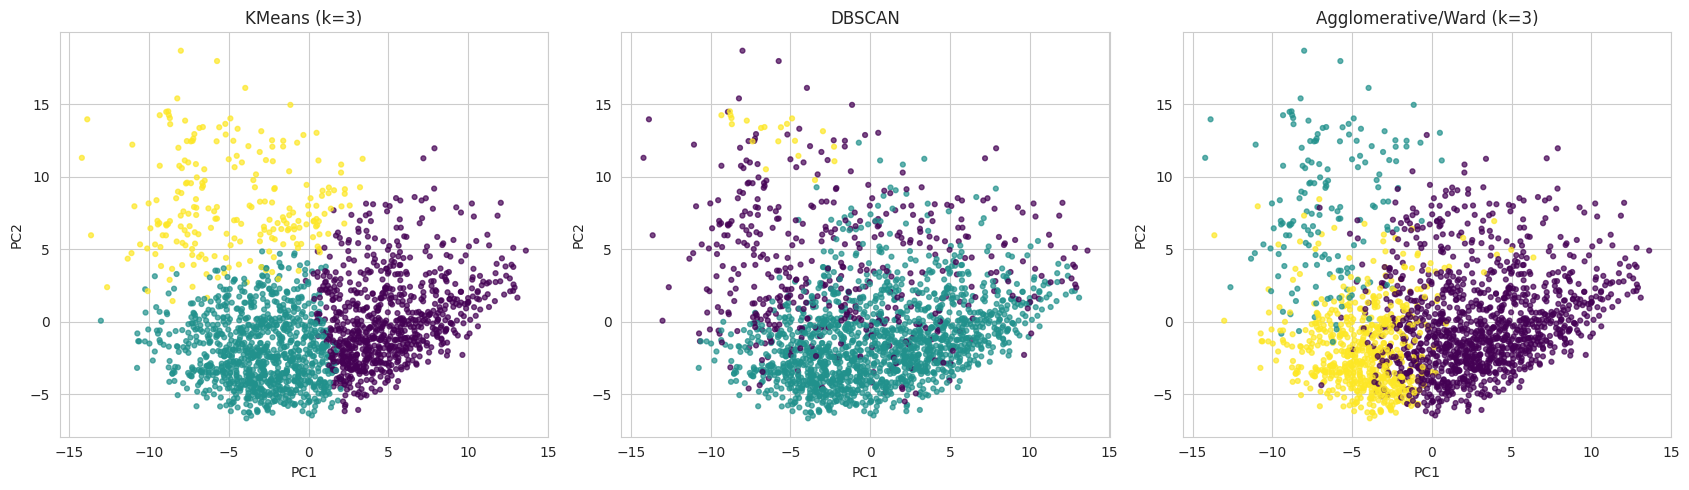

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

for ax, labels, title in zip(
    axes,
    [kmeans_labels, dbscan_labels, agglo_labels],
    ['KMeans (k=3)', 'DBSCAN', 'Agglomerative/Ward (k=3)']
):
    scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels, cmap='viridis', s=12, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')

plt.tight_layout()
plt.show()

**Selección: KMeans (k=3).**

- Tiene el **mejor silhouette** entre las soluciones que clasifican a (casi) todas las comunidades.
- **DBSCAN** no logra una partición útil: encuentra básicamente un cluster gigante más micro-clusters de atípicos extremos y descarta como "ruido" a cientos de comunidades — coherente con que estos datos no tienen una estructura de densidad discontinua, sino un continuo socioeconómico. Su silhouette más alto es engañoso: se calcula ignorando el ruido, sobre grupos minúsculos fácilmente separables por ser outliers.
- **Agglomerative/Ward** da una partición razonable y **moderadamente similar a KMeans** (ARI/AMI indican acuerdo por encima del azar pero lejos de ser idéntica), lo que es una buena señal de que la estructura de 3 grupos es real y no un artefacto de un único algoritmo. Sin embargo, KMeans tiene mejores métricas internas y tamaños de cluster más balanceados.

Por lo tanto, se usa **la partición de KMeans con k=3** para la interpretación final.

### 3d. Interpretación de los clusters


In [23]:
cluster_target = pd.DataFrame({'cluster': kmeans_labels, 'ViolentCrimesPerPop': target.values})

summary_target = cluster_target.groupby('cluster')['ViolentCrimesPerPop'].describe().round(3)
summary_target

,count,mean,std,min,25%,50%,75%,max
cluster,,,,,,,,
0,798.0,0.105,0.097,0.00,0.040,0.080,0.140,0.83
1,976.0,0.295,0.241,0.00,0.110,0.220,0.420,1.00
2,220.0,0.466,0.267,0.02,0.248,0.395,0.633,1.00


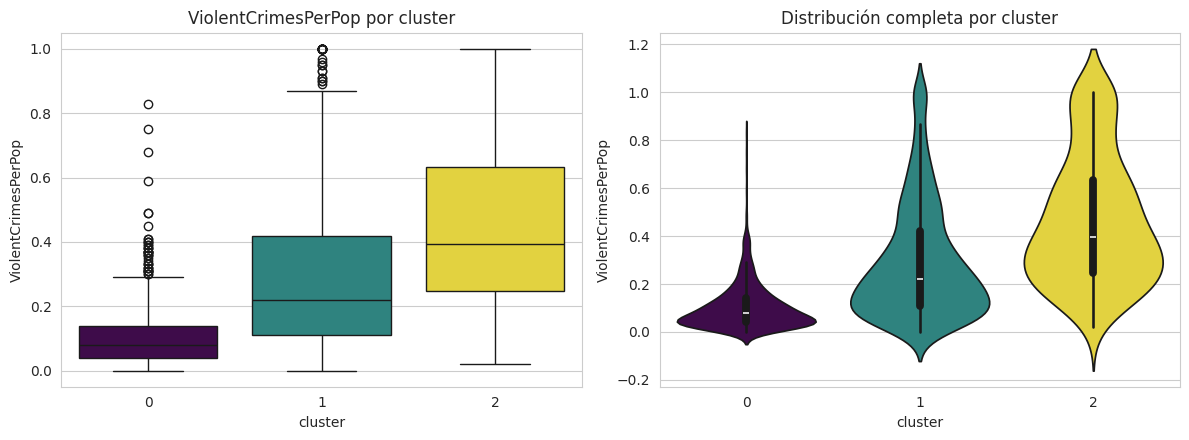

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.boxplot(x='cluster', y='ViolentCrimesPerPop', data=cluster_target,
            hue='cluster', palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('ViolentCrimesPerPop por cluster')

sns.violinplot(x='cluster', y='ViolentCrimesPerPop', data=cluster_target,
                hue='cluster', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Distribución completa por cluster')

plt.tight_layout()
plt.show()

In [25]:
from scipy.stats import kruskal

groups = [cluster_target.loc[cluster_target.cluster == c, 'ViolentCrimesPerPop'].values
          for c in sorted(cluster_target.cluster.unique())]
stat, p_value = kruskal(*groups)
print(f"Kruskal-Wallis H = {stat:.1f}, p-value = {p_value:.2e}")

Kruskal-Wallis H = 628.0, p-value = 4.30e-137


Los tres clusters muestran niveles de criminalidad **claramente distintos** y el test de Kruskal-Wallis (no paramétrico, apropiado dado que la variable está sesgada) rechaza con altísima significancia la hipótesis de que las tres distribuciones son iguales. Es una validación fuerte de la hipótesis inicial: **la estructura socioeconómica que capturan PCA + KMeans, sin ver el target ni una sola vez, está fuertemente asociada al nivel de violencia**.

#### Perfil socioeconómico de cada cluster



In [26]:
key_feats = [
    'medIncome', 'PctPopUnderPov', 'PctUnemployed', 'PctBSorMore',
    'racepctblack', 'racePctWhite', 'PctForeignBorn',
    'PctFam2Par', 'PctIlleg', 'PopDens', 'PctVacantBoarded', 'MedRent'
]

profile = X[key_feats].copy()
profile['cluster'] = kmeans_labels
profile_means = profile.groupby('cluster').mean().round(3).T
profile_means.columns = [f'Cluster {c}' for c in profile_means.columns]
profile_means

,Cluster 0,Cluster 1,Cluster 2
medIncome,0.562,0.212,0.292
PctPopUnderPov,0.102,0.429,0.471
PctUnemployed,0.217,0.434,0.581
PctBSorMore,0.497,0.277,0.249
racepctblack,0.070,0.259,0.225
racePctWhite,0.873,0.729,0.429
PctForeignBorn,0.227,0.105,0.666
PctFam2Par,0.784,0.497,0.490
PctIlleg,0.104,0.319,0.471
PopDens,0.207,0.189,0.522


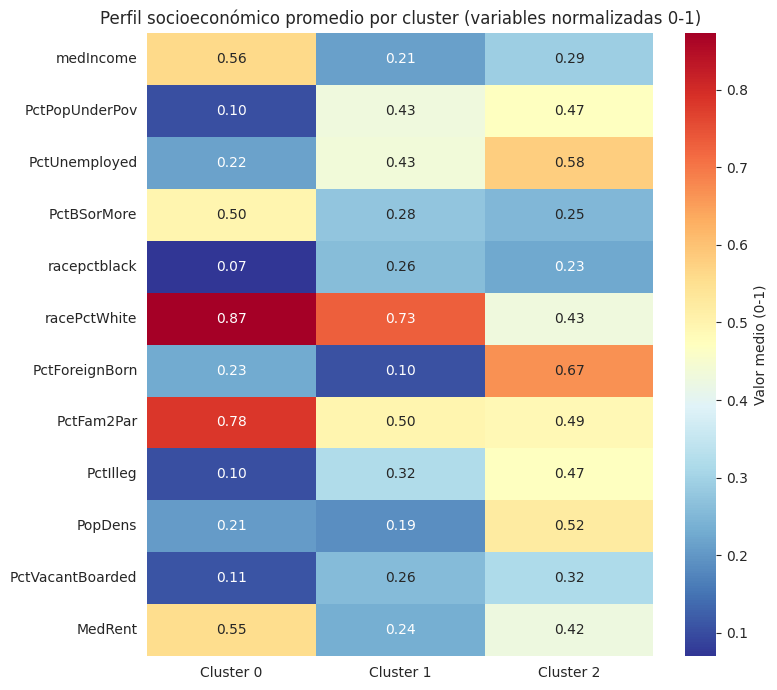

In [27]:
plt.figure(figsize=(8, 7))
sns.heatmap(profile_means, annot=True, fmt='.2f', cmap='RdYlBu_r', cbar_kws={'label': 'Valor medio (0-1)'})
plt.title('Perfil socioeconómico promedio por cluster (variables normalizadas 0-1)')
plt.tight_layout()
plt.show()

Característica de los cluster:

- **Cluster 0 — Comunidades acomodadas de baja densidad** (n≈798): ingreso medio alto, pobreza y desempleo bajos, alta proporción de adultos con título universitario, mayoría blanca, alta proporción de familias con dos padres, baja densidad poblacional (suburbios/pueblos chicos). → **Menor criminalidad del dataset** (media ≈0.11).
- **Cluster 1 — Comunidades de bajos ingresos, de baja densidad y poca inmigración** (n≈976): ingreso bajo, pobreza y desempleo considerablemente más altos que el cluster 0, baja proporción de población extranjera, densidad poblacional también baja (zonas rurales/pequeñas ciudades en declive económico). → **Criminalidad intermedia** (media ≈0.30).
- **Cluster 2 — Núcleos urbanos densos, con alta pobreza e inmigración** (n≈220, el grupo más chico): la mayor pobreza y desempleo del dataset, mayor densidad poblacional (zonas urbanas), mayor proporción de población extranjera, mayor proporción de vivienda vacía/tapiada (señal de deterioro urbano), menor proporción de familias con dos padres. → **Mayor criminalidad del dataset, y por lejos la más dispersa** (media ≈0.47, con alta variabilidad).

El patrón es consistente con literatura clásica de criminología urbana: **pobreza, desempleo, desorganización familiar y densidad urbana** co-ocurren con mayor violencia, mientras que estabilidad económica y familiar co-ocurre con menor violencia. Importante: esto es **correlacional**, no causal, y corresponde a un nivel de análisis **agregado por comunidad** (no se puede inferir nada sobre individuos — falacia ecológica).

#### Comunidades representativas de cada cluster



In [28]:
from scipy.spatial.distance import cdist

for c in sorted(np.unique(kmeans_labels)):
    mask = kmeans_labels == c
    idxs = np.where(mask)[0]
    centroid = kmeans.cluster_centers_[c]
    dists = cdist(X_pca[idxs], centroid.reshape(1, -1)).ravel()
    closest = idxs[np.argsort(dists)[:5]]
    reps = community_names.iloc[closest].tolist()
    print(f"Cluster {c} (n={mask.sum()}) - comunidades más representativas: {reps}")

Cluster 0 (n=798) - comunidades más representativas: ['Windsortown', 'Shrewsburytown', 'Wallingfordtown', 'Westboroughtown', 'Betheltown']
Cluster 1 (n=976) - comunidades más representativas: ['Florencecity', 'Templecity', 'NewAlbanycity', 'Pascagoulacity', 'Davenportcity']
Cluster 2 (n=220) - comunidades más representativas: ['SantaMariacity', 'Coltoncity', 'Pittsburgcity', 'Salinascity', 'ChulaVistacity']


Se observan nombres consistentes con el perfil de cada cluster: el cluster 0 agrupa pueblos/suburbios de Connecticut y Massachusetts (típicamente acomodados), el cluster 1 mezcla ciudades medianas de distintos estados con economías más golpeadas, y el cluster 2 está dominado por ciudades californianas densamente pobladas y con alta población inmigrante.

#### ¿Qué estructura captura el clustering?

En definitiva, PCA + KMeans recuperan — a partir de 100 variables censales y sin ver nunca el target — un **eje latente de nivel socioeconómico/urbanización** que resulta ser el principal correlato observable de la violencia en este dataset. Esto es información útil en sí misma: sugiere que políticas o intervenciones orientadas a pobreza, empleo y estabilidad familiar en zonas urbanas densas actúan, indirectamente, sobre el mismo eje que explica gran parte de la variación en criminalidad entre comunidades.

---
## 4. Visualización e interpretación con UMAP


In [29]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, init='pca', learning_rate='auto')
X_tsne = tsne.fit_transform(X_scaled)
X_tsne.shape

(1994, 2)

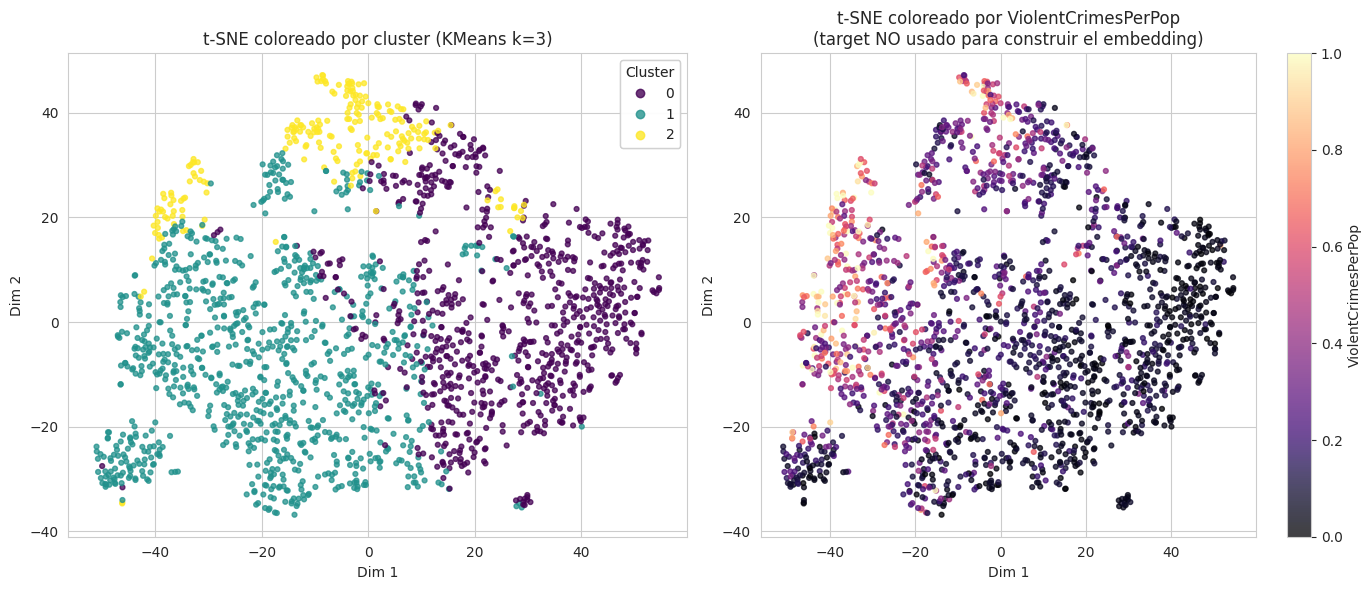

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sc0 = axes[0].scatter(X_tsne[:, 0], X_tsne[:, 1], c=kmeans_labels, cmap='viridis', s=12, alpha=0.75)
axes[0].set_title('t-SNE coloreado por cluster (KMeans k=3)')
axes[0].set_xlabel('Dim 1'); axes[0].set_ylabel('Dim 2')
legend0 = axes[0].legend(*sc0.legend_elements(), title='Cluster', loc='best')
axes[0].add_artist(legend0)

sc1 = axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=target, cmap='magma', s=12, alpha=0.75)
axes[1].set_title('t-SNE coloreado por ViolentCrimesPerPop\n(target NO usado para construir el embedding)')
axes[1].set_xlabel('Dim 1'); axes[1].set_ylabel('Dim 2')
plt.colorbar(sc1, ax=axes[1], label='ViolentCrimesPerPop')

plt.tight_layout()
plt.show()

**Lectura del embedding 2D:**

- Cada punto es una comunidad; puntos cercanos tienen perfiles censales similares en el espacio original de 100 variables.
- Al colorear por cluster de KMeans (panel izquierdo), los tres grupos ocupan regiones mayormente diferenciadas del plano, aunque con zonas de **solapamiento/transición** en los bordes — coherente con  DBSCAN: la estructura es más un **continuo con regiones de mayor densidad** que clusters discretos y perfectamente separados.
- Al colorear por `ViolentCrimesPerPop` sin que el embedding lo haya usado (panel derecho), se ve un **gradiente de color** que corre en la misma dirección aproximada que separa los clusters: las zonas correspondientes al cluster 2 (alta pobreza/densidad urbana) concentran los tonos más intensos (alta criminalidad), mientras que la región del cluster 0 es sistemáticamente más clara (baja criminalidad). Esto es una confirmación visual, independiente del clustering, de la misma conclusión: **la estructura socioeconómica latente de los datos está alineada con el nivel de violencia**, aunque la frontera no es nítida — hay comunidades de perfil intermedio con criminalidad intermedia, lo cual es exactamente lo que se espera de un fenómeno social continuo y no de categorías discretas.
- También se aprecian **puntos aislados** lejos de las regiones densas (comunidades con combinaciones atípicas de variables, por ejemplo densidad extrema o composición demográfica inusual) — los mismos tipos de casos que DBSCAN marcaba como ruido o micro-clusters.


---
## Conclusiones

1. **Reducción de dimensionalidad:** 100 variables censales/socioeconómicas se comprimen a ~23 componentes principales conservando el 90% de la varianza. Las primeras componentes están dominadas por un eje de **nivel socioeconómico** (pobreza, ingreso, estructura familiar) y un eje de **urbanización/inmigración**, lo que ya anticipa la estructura que después encuentra el clustering.

2. **Clustering:** de los tres algoritmos comparados, **KMeans (k=3)** ofrece la partición más clara, balanceada y con mejores métricas internas. DBSCAN confirma que **no hay fronteras de densidad naturales** entre grupos (más bien un continuo), y Agglomerative/Ward valida con un acuerdo moderado-alto que la estructura de 3 grupos encontrada por KMeans no es arbitraria.

3. **Interpretación:** sin usar nunca el target, los 3 clusters resultan tener niveles de `ViolentCrimesPerPop` significativamente distintos (Kruskal-Wallis, p≈0). El cluster de comunidades acomodadas y de baja densidad tiene la menor criminalidad; el cluster de núcleos urbanos densos, con alta pobreza/desempleo y mayor población inmigrante, tiene la mayor criminalidad y también la mayor dispersión interna.

4. **UMAP/t-SNE:** la visualización 2D no lineal confirma, de manera totalmente independiente del clustering, que existe un gradiente continuo asociado a la violencia a lo largo de la misma estructura socioeconómica — reforzando que se trata de un fenómeno gradual más que de categorías discretas.

**Hipótesis inicial:** se confirma. La estructura latente que emerge de variables puramente censales (sin ver crimen) está fuertemente asociada al nivel de violencia observado, lo que es consistente con el consenso de la criminología social sobre los determinantes estructurales del crimen (pobreza concentrada, desempleo, desorganización familiar, densidad urbana).

